# 06 Time-varying batter effects

The package model holds each batter's effect fixed over every training season, so a
batter's 2010 form counts the same as his 2023 form. This notebook lets batter effects
drift from season to season and asks whether that predicts later seasons better.

**The model.** The package model (phase, role, experience, linear season trend, partially
pooled batter and bowler effects) plus a random walk for each batter:

$$\text{bat}_{b,s} = \sigma_\beta z_b - \sigma_w \sum_{j=s}^{T-1} e_{b,j}, \qquad
e_{b,j} \sim N(0, 1),$$

anchored at the last training season $T$, so $\sigma_\beta z_b$ is the batter's effect
*now*, and earlier seasons drift away from it. A forecast for season $T + h$ adds $h$
more random-walk steps. Only batters with 300 or more training balls get a walk (144 of
them when fitting on 2008 to 2022); for the rest a season-by-season path cannot be
estimated, and they keep a fixed effect. Bowler effects stay fixed: their pooling scale
is about a third of the batters'.

**The rule, set at the end of `05` before this notebook was run:** the walk is kept only
if it lowers mean log loss over the five validation seasons 2019 to 2023 (fit on every
earlier season each time). The test seasons are scored once, for the record.

In [1]:
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy.special import expit, logit

from cricket_ba import hierarchical as H
from cricket_ba.evaluate import difference_interval, match_bootstrap, scores
from cricket_ba.features import add_experience

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, RESULTS = ROOT / "figures", ROOT / "results"
SEED = 20261112
FIRST, TEST_SEASONS, MIN_BALLS = 2008, [2024, 2025], 300

balls = pd.read_parquet(ROOT / "data" / "legal_balls.parquet")
if "experience" not in balls:
    balls = add_experience(balls)
train = balls[~balls.season.isin(TEST_SEASONS)].reset_index(drop=True)
test = balls[balls.season.isin(TEST_SEASONS)].reset_index(drop=True)
print("model terms:", H.TERMS, "| sampler:", H.SAMPLER)

model terms: ('role', 'experience') | sampler: {'draws': 1000, 'tune': 1000, 'chains': 4, 'cores': 4, 'target_accept': 0.95}


## Do batters' rates move between seasons?

The six batters with the most training balls, season by season, with binomial 95%
intervals. Most of the movement is within the intervals.

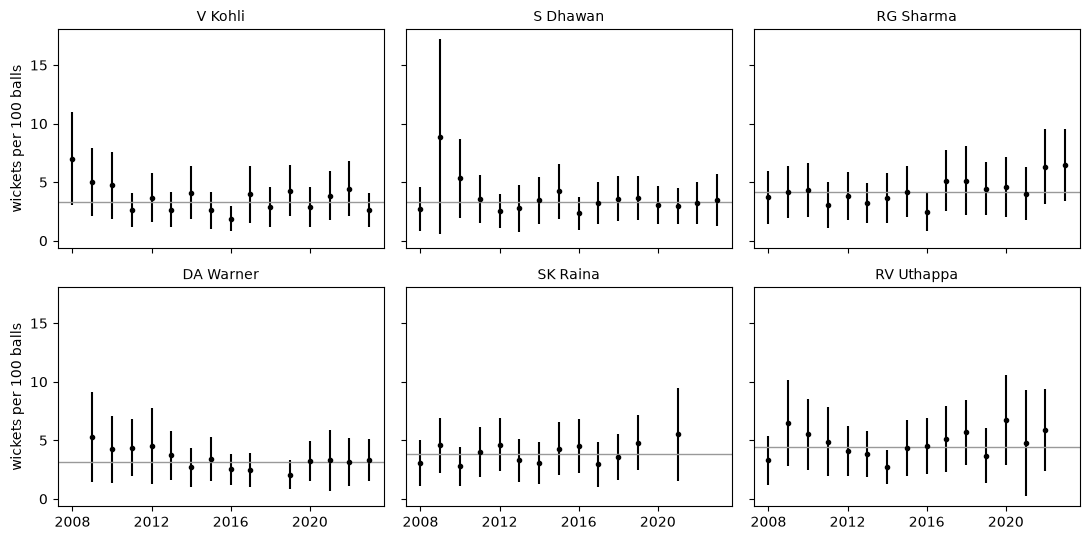

In [2]:
top6 = train.batter_id.value_counts().index[:6]
names = train.drop_duplicates("batter_id").set_index("batter_id")["batter"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True, sharey=True)
for ax, b in zip(axes.flat, top6):
    g = train[train.batter_id == b].groupby("season")["wicket"].agg(["mean", "size"])
    se = np.sqrt(g["mean"].clip(0.005) * (1 - g["mean"]) / g["size"])
    ax.errorbar(g.index, 100 * g["mean"], yerr=196 * se, fmt="o", color="k", ms=3)
    ax.axhline(100 * train.loc[train.batter_id == b, "wicket"].mean(), color="0.6", lw=1)
    ax.set_title(names[b], fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("wickets per 100 balls")
for ax in axes[-1]:
    ax.set_xticks([2008, 2012, 2016, 2020])
fig.tight_layout()
fig.savefig(FIG / "batter_seasons.png", dpi=150)

## The model

In [3]:
def fit(df, walk, seed):
    """Fit the package model (``walk=False``) or the random-walk version."""
    idx = H.make_index(df)
    cells = H.aggregate(df, idx)
    seasons = np.arange(FIRST, df.season.max() + 1)
    if not walk:
        with H.build_model(cells, idx):
            idata = pm.sample(**H.SAMPLER, random_seed=seed, progressbar=False)
        return idx, pd.Index([]), idata
    n = df.groupby("batter_id").size()
    walkers = pd.Index(n[n >= MIN_BALLS].index)
    w_idx = walkers.get_indexer(cells.batter_id)
    s_idx = (cells.season - FIRST).to_numpy()
    has = np.where(w_idx >= 0)[0]
    coords = {"phase": list(idx.phases), "batter": list(idx.batters),
              "bowler": list(idx.bowlers), "walker": list(walkers), "step": seasons[:-1],
              "season": seasons}
    for t in H.TERMS:
        coords[t] = list(H.LEVELS[t])
        coords[f"{t}_vs_ref"] = list(H.LEVELS[t][1:])
    with pm.Model(coords=coords):
        alpha = pm.Normal("alpha", mu=logit(0.05), sigma=0.5, dims="phase")
        sigma_bat = pm.HalfNormal("sigma_bat", 0.5)
        sigma_bowl = pm.HalfNormal("sigma_bowl", 0.5)
        bat = pm.Deterministic("bat", sigma_bat * pm.Normal("z_bat", 0, 1, dims="batter"),
                               dims="batter")
        bowl = pm.Deterministic("bowl", sigma_bowl * pm.Normal("z_bowl", 0, 1, dims="bowler"),
                                dims="bowler")
        beta = pm.Normal("beta", 0, 0.5)
        eta = (alpha[cells.phase_idx.to_numpy()] + bat[cells.bat_idx.to_numpy()]
               + bowl[cells.bowl_idx.to_numpy()] + beta * H.season_x(cells.season))
        for t in H.TERMS:
            free = pm.Normal(f"{t}_free", 0, 0.5, dims=f"{t}_vs_ref")
            eff = pm.Deterministic(f"{t}_eff", pt.concatenate([pt.zeros(1), free]), dims=t)
            eta = eta + eff[cells[f"{t}_idx"].to_numpy()]
        sigma_walk = pm.HalfNormal("sigma_walk", 0.1)
        e = pm.Normal("z_walk", 0, 1, dims=("walker", "step"))
        back = pt.cumsum(e[:, ::-1], axis=1)[:, ::-1]
        offset = pm.Deterministic(
            "walk", pt.concatenate([-sigma_walk * back, pt.zeros((len(walkers), 1))], axis=1),
            dims=("walker", "season"))
        eta = pt.inc_subtensor(eta[has], offset[w_idx[has], s_idx[has]])
        pm.Binomial("k", n=cells.n.to_numpy(), logit_p=eta, observed=cells.k.to_numpy())
        idata = pm.sample(**H.SAMPLER, random_seed=seed, progressbar=False)
    return idx, walkers, idata


def predict(df, idx, idata, walk, seed):
    """Posterior-mean wicket probability per ball of ``df`` (seasons after training).

    With the walk, every batter gets one random-walk step per season ahead, drawn
    afresh in each posterior draw.
    """
    c = H.aggregate(df)
    P = H.predict_draws(c, idx, H.Draws.from_idata(idata), seed)
    if walk:
        post = idata.posterior.stack(s=("chain", "draw"))
        sw = post["sigma_walk"].to_numpy()
        last = int(post["season"][-1])
        bats = pd.Index(c.batter_id.unique())
        z = np.random.default_rng(seed + 1).standard_normal((len(bats), len(sw)))
        h = np.sqrt(c.season.to_numpy() - last)[:, None]
        P = expit(logit(P) + h * sw[None, :] * z[bats.get_indexer(c.batter_id)])
    c["p"] = P.mean(1)
    return df.merge(c[H.KEYS + ["p"]], on=H.KEYS, how="left")["p"].to_numpy()


def diagnostics(idata, walk):
    names = ["alpha", "sigma_bat", "sigma_bowl", "beta", "z_bat", "z_bowl"]
    names += [f"{t}_free" for t in H.TERMS] + (["sigma_walk", "z_walk"] if walk else [])
    s = az.summary(idata, var_names=names, round_to=None)
    return {"divergences": int(idata.sample_stats["diverging"].sum()),
            "max rhat": round(float(s.r_hat.max()), 3), "min ess bulk": int(s.ess_bulk.min())}

## Five-season validation

In [4]:
MODELS = {"package model": False, "random walk": True}
rows, preds, sigma_walk = [], [], {}
for s in range(2019, 2024):
    tr_s, va_s = train[train.season < s], train[train.season == s].reset_index(drop=True)
    for name, walk in MODELS.items():
        idx, walkers, idata = fit(tr_s, walk, SEED)
        va_s[f"p_{name}"] = predict(va_s, idx, idata, walk, SEED)
        rows.append({"model": name, "val season": s, "walkers": len(walkers),
                     **diagnostics(idata, walk), **scores(va_s.wicket, va_s[f"p_{name}"])})
        if walk:
            sigma_walk[s] = az.summary(idata, var_names=["sigma_walk"]).iloc[0]
    preds.append(va_s[["match_id", "wicket"] + [f"p_{n}" for n in MODELS]])
cv = pd.DataFrame(rows)
cv.to_csv(RESULTS / "time_varying_cv.csv", index=False)
display(cv.pivot(index="val season", columns="model", values="log_loss").round(6))
display(cv[["model", "val season", "walkers", "divergences", "max rhat", "min ess bulk"]])
display(pd.DataFrame(sigma_walk).T[["mean", "sd", "hdi_3%", "hdi_97%", "r_hat"]])
cv.groupby("model")[["log_loss", "brier"]].mean().round(6)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma_bat, sigma_bowl, z_bat, z_bowl, beta, role_free, experience_free]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 232 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


... (35 outputs left out)

model,package model,random walk
val season,,
2019,0.182294,0.182304
2020,0.179649,0.179639
2021,0.189925,0.189913
2022,0.194275,0.194286
2023,0.195782,0.195781


,model,val season,walkers,divergences,max rhat,min ess bulk
0,package model,2019,0,0,1.01,857
1,random walk,2019,119,0,1.01,761
2,package model,2020,0,0,1.01,1004
3,random walk,2020,126,0,1.01,868
4,package model,2021,0,0,1.01,796
5,random walk,2021,130,0,1.01,607
6,package model,2022,0,0,1.01,820
7,random walk,2022,135,0,1.01,546
8,package model,2023,0,0,1.01,1106
9,random walk,2023,144,0,1.01,497


,mean,sd,hdi_3%,hdi_97%,r_hat
2019,0.014,0.010,0.0,0.032,1.01
2020,0.013,0.010,0.0,0.031,1.01
2021,0.014,0.011,0.0,0.034,1.00
2022,0.016,0.011,0.0,0.035,1.01
2023,0.014,0.010,0.0,0.032,1.00


,log_loss,brier
model,,
package model,0.188385,0.04506
random walk,0.188385,0.04506


In [5]:
cvp = pd.concat(preds, ignore_index=True)
cb = match_bootstrap(cvp, [f"p_{n}" for n in MODELS], n_boot=1000, seed=SEED)
cv_diff = difference_interval(cb, "p_random walk", "p_package model")
cv_diff.to_csv(RESULTS / "time_varying_cv_difference.csv")
mean_ll = cv.groupby("model")["log_loss"].mean()
chosen = mean_ll.idxmin()
print("chosen by the rule:", chosen)
cv_diff

chosen by the rule: random walk


,2.5%,median,97.5%
log_loss,-5.758382e-06,-1.011989e-07,5.471191e-06
brier,-5.687335e-07,2.956924e-08,6.254405e-07


## Test seasons, for the record

In [6]:
tp = test[["match_id", "wicket"]].copy()
test_rows, test_fits = [], {}
for name, walk in MODELS.items():
    idx, walkers, idata = fit(train, walk, SEED)
    test_fits[name] = (idx, walkers, idata)
    tp[f"p_{name}"] = predict(test, idx, idata, walk, SEED)
    test_rows.append({"model": name, **diagnostics(idata, walk),
                      **scores(test.wicket, tp[f"p_{name}"]),
                      "mean predicted": tp[f"p_{name}"].mean()})
tt = pd.DataFrame(test_rows)
tt["observed"] = test.wicket.mean()
tt.to_csv(RESULTS / "time_varying_test.csv", index=False)
tb = match_bootstrap(tp, [f"p_{n}" for n in MODELS], n_boot=1000, seed=SEED)
display(tt.round(6))
difference_interval(tb, "p_random walk", "p_package model")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma_bat, sigma_bowl, z_bat, z_bowl, beta, role_free, experience_free]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 412 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma_bat, sigma_bowl, z_bat, z_bowl, beta, role_free, experience_free, sigma_walk, z_walk]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1604 seconds.


,model,divergences,max rhat,min ess bulk,log_loss,brier,mean predicted,observed
0,package model,0,1.01,896,0.196812,0.047544,0.049761,0.050357
1,random walk,0,1.01,499,0.196809,0.047543,0.049754,0.050357


,2.5%,median,97.5%
log_loss,-0.000012,-2.238630e-06,9.225737e-06
brier,-0.000001,-3.069098e-07,9.226427e-07


## How far do batters drift?

The fitted walks for the six batters above (fit on 2008 to 2023): posterior mean and 80%
interval of the effect in each season, on the logit scale, against the fixed effect of
the package model.

             mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
sigma_walk  0.015  0.010   0.000    0.032        0.0      0.0     499.0     840.0    1.0
sigma_bat   0.170  0.017   0.137    0.200        0.0      0.0    1183.0    1969.0    1.0


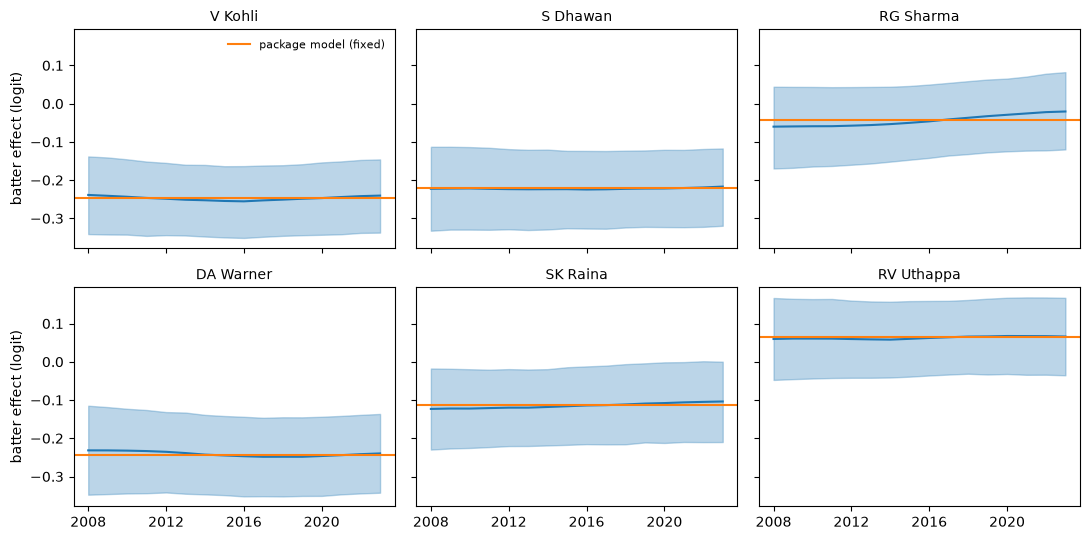

In [7]:
idx_w, walkers_w, idata_w = test_fits["random walk"]
idx_p, _, idata_p = test_fits["package model"]
post_w = idata_w.posterior.stack(s=("chain", "draw"))
post_p = idata_p.posterior.stack(s=("chain", "draw"))
print(az.summary(idata_w, var_names=["sigma_walk", "sigma_bat"]).to_string())
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True, sharey=True)
for ax, b in zip(axes.flat, top6):
    path = (post_w["walk"].sel(walker=b) + post_w["bat"].sel(batter=b)).transpose("season", "s")
    q = path.quantile([0.1, 0.9], "s").to_numpy()
    ax.fill_between(path.season, q[0], q[1], color="C0", alpha=0.3)
    ax.plot(path.season, path.mean("s"), "C0-")
    ax.axhline(float(post_p["bat"].sel(batter=b).mean()), color="C1", lw=1.5,
               label="package model (fixed)")
    ax.set_title(names[b], fontsize=10)
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("batter effect (logit)")
for ax in axes[-1]:
    ax.set_xticks([2008, 2012, 2016, 2020])
fig.tight_layout()
fig.savefig(FIG / "batter_walks.png", dpi=150)

In [8]:
# total drift over the 16 training seasons implied by the walk, against the spread
# between batters
sw = post_w["sigma_walk"].to_numpy()
sb = post_w["sigma_bat"].to_numpy()
drift = pd.Series({"sd of 15-season drift (median)": np.median(np.sqrt(15) * sw),
                   "sigma_bat (median)": np.median(sb)})
drift.round(3)

sd of 15-season drift (median)    0.051
sigma_bat (median)                0.169
dtype: float64

## Conclusion

* **A tie.** Over the five validation seasons the random walk and the package model have
  the same mean log loss to six decimal places (0.188385). The pooled difference is
  -0.0000001 with a 95% interval of -0.000006 to +0.000005. On the test seasons the gap
  is -0.000002 (-0.000012 to +0.000009).
* **The decision.** Read literally, the rule set in `05` ("keep the walk if it lowers mean
  validation log loss") picks the walk by 0.0000001, which is a rounding difference, not
  evidence. I treat it as a tie and keep the simpler package model: the walk samples more
  slowly, has lower effective sample sizes (497 against 896 at worst) and predicts no
  better. This departs from the letter of the rule, towards the simpler model rather than
  towards anything the test seasons favoured.
* **Why it ties.** Batters barely drift. The step per season is $\sigma_w = 0.015$ (94%
  HDI 0 to 0.032), so over the 15 training steps a batter's effect moves by about 0.05 on
  the logit scale, against a spread between batters of $\sigma_\beta = 0.17$. The fitted
  paths of the six batters with most balls are close to flat, well inside their 80%
  intervals. Given who the batter is, his role and his experience, his season-to-season
  form adds almost nothing a ball-level model can detect.
* **What this does not show.** Only batters with 300 or more training balls had a walk,
  and a binomial outcome at about 5% carries little information per season, so small
  real changes in form could be present and undetectable here.